<a href="https://colab.research.google.com/github/Dakhway-Amaan/INFO-5100-LAB-08/blob/main/INFO_5100_LAB_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)   # folder where we'll save chart images

In [2]:
import kagglehub
path = kagglehub.dataset_download("shivamb/netflix-shows")
df = pd.read_csv(os.path.join(path, "netflix_titles.csv"))

Using Colab cache for faster access to the 'netflix-shows' dataset.


In [3]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [5]:
df.isnull().sum()     # director, cast, country have many missing values

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [6]:
# A few rows have the duration typed into the rating column by mistake (e.g. "74 min")
mask = df["rating"].str.contains("min", na=False)
df.loc[mask, "duration"] = df.loc[mask, "rating"]
df.loc[mask, "rating"] = None

# Convert date_added text (e.g. "September 25, 2021") to real dates
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="mixed", errors="coerce")
df["year_added"] = df["date_added"].dt.year

# Fill missing countries so they don't break the country chart
df["country"] = df["country"].fillna("Unknown")

# Movie length in minutes as a number
movies = df[df["type"] == "Movie"].copy()
movies["minutes"] = movies["duration"].str.extract(r"(\d+)")[0].astype(float)

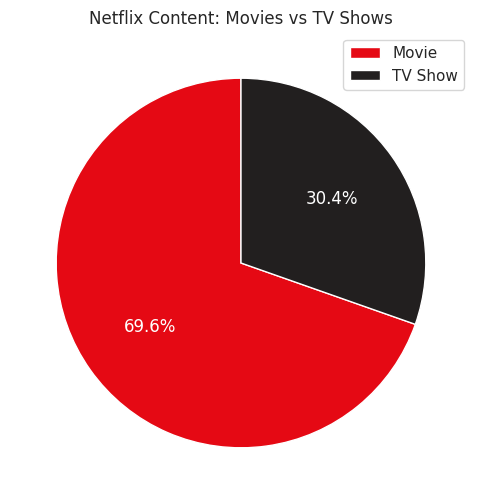

In [7]:
type_counts = df["type"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(type_counts, labels=type_counts.index, autopct="%1.1f%%",
        colors=["#E50914", "#221f1f"], startangle=90,
        textprops={"color": "white", "fontsize": 12})
plt.legend(type_counts.index, loc="upper right")
plt.title("Netflix Content: Movies vs TV Shows")
plt.savefig("charts/1_movies_vs_tvshows_pie.png", dpi=150, bbox_inches="tight")
plt.show()

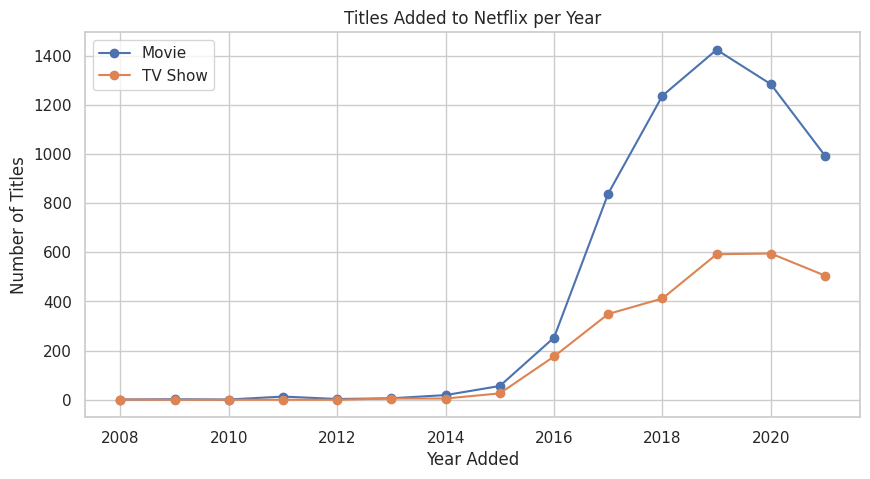

In [8]:
added = (df.dropna(subset=["year_added"])
           .groupby(["year_added", "type"]).size()
           .unstack(fill_value=0))

plt.figure(figsize=(10, 5))
for content_type in added.columns:
    plt.plot(added.index, added[content_type], marker="o", label=content_type)
plt.title("Titles Added to Netflix per Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.legend()
plt.savefig("charts/2_titles_added_per_year.png", dpi=150, bbox_inches="tight")
plt.show()

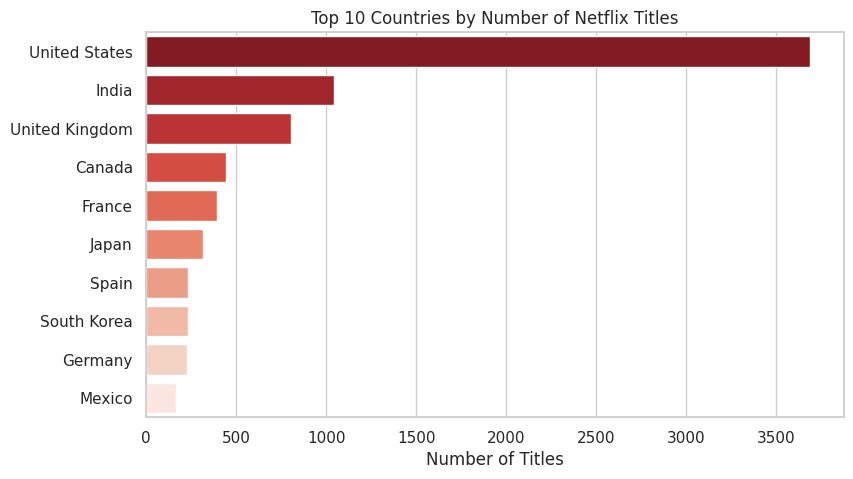

In [9]:
# Many titles list several countries ("United States, India"), so split them up
countries = df["country"].str.split(",").explode().str.strip()
countries = countries[(countries != "Unknown") & (countries != "")]
top_countries = countries.value_counts().head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_countries.values, y=top_countries.index,
            hue=top_countries.index, palette="Reds_r", legend=False)
plt.title("Top 10 Countries by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("")
plt.savefig("charts/3_top_countries_bar.png", dpi=150, bbox_inches="tight")
plt.show()

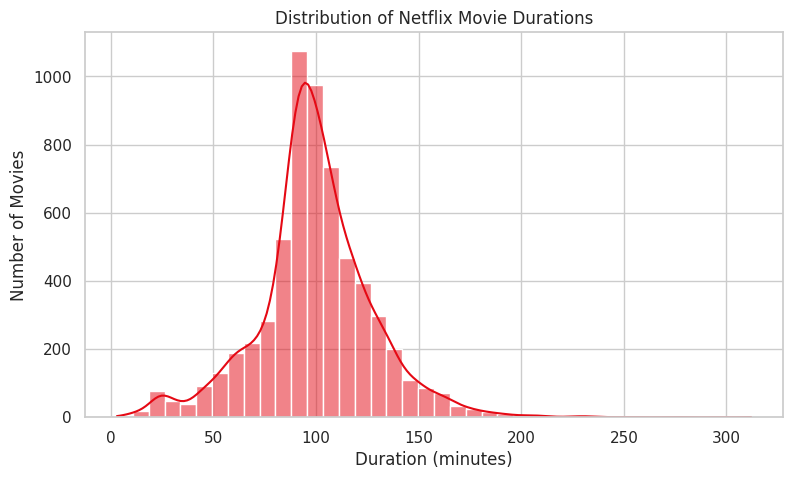

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(movies["minutes"].dropna(), bins=40, kde=True, color="#E50914")
plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.savefig("charts/4_movie_duration_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

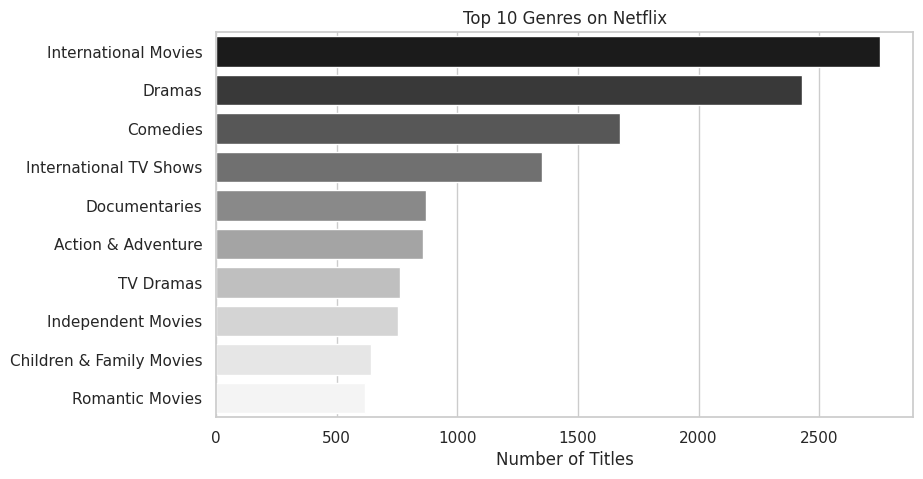

In [11]:
genres = df["listed_in"].str.split(",").explode().str.strip()
top_genres = genres.value_counts().head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_genres.values, y=top_genres.index,
            hue=top_genres.index, palette="Greys_r", legend=False)
plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("")
plt.savefig("charts/5_top_genres_bar.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
!zip -r charts.zip charts
from google.colab import files
files.download("charts.zip")

updating: charts/ (stored 0%)
updating: charts/3_top_countries_bar.png (deflated 21%)
updating: charts/1_movies_vs_tvshows_pie.png (deflated 9%)
updating: charts/2_titles_added_per_year.png (deflated 10%)
updating: charts/5_top_genres_bar.png (deflated 22%)
updating: charts/4_movie_duration_histogram.png (deflated 10%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>